In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
from google.colab import files

uploaded = files.upload()

Saving Online Retail.xlsx to Online Retail.xlsx


In [3]:
df = pd.read_excel("Online Retail.xlsx")

In [4]:
print("First 5 rows:")
display(df.head())

print("Last 5 rows:")
display(df.tail())

print("Dataset shape:")
print(df.shape)

print("Dataset information:")
df.info()

print("Statistical summary:")
display(df.describe())

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Last 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


Dataset shape:
(541909, 8)
Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
Statistical summary:


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [5]:
# Missing values
print("Missing values:")
print(df.isnull().sum())

# Duplicate rows
print("Duplicates:", df.duplicated().sum())

# Unique customers
print("Unique customers:", df["CustomerID"].nunique())

# Unique invoices
print("Unique invoices:", df["InvoiceNo"].nunique())

Missing values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Duplicates: 5268
Unique customers: 4372
Unique invoices: 25900


In [6]:
df = df.drop_duplicates()

# Convert date to datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Remove missing customer IDs
df = df.dropna(subset=["CustomerID"])

# Convert customer ID to integer
df["CustomerID"] = df["CustomerID"].astype(int)

# Remove invalid prices and quantities
df = df[df["UnitPrice"] > 0]
df = df[df["Quantity"] != 0]

# Create revenue column
df["Revenue"] = df["Quantity"] * df["UnitPrice"]

display(df.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


In [7]:
total_revenue = df["Revenue"].sum()

total_customers = df["CustomerID"].nunique()

total_orders = df["InvoiceNo"].nunique()

print("Total Revenue:", total_revenue)
print("Total Customers:", total_customers)
print("Total Orders:", total_orders)

Total Revenue: 8278519.424000001
Total Customers: 4371
Total Orders: 22186


In [8]:
average_order_value = total_revenue / total_orders

print("Average Order Value:", average_order_value)

Average Order Value: 373.14159487965384


In [9]:
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,
    "InvoiceNo": "nunique",
    "Revenue": "sum"
})

rfm.columns = ["Recency", "Frequency", "Monetary"]

display(rfm.head())

,Recency,Frequency,Monetary
CustomerID,,,
12346,326,2,0.00
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40


In [10]:
top_customers = rfm.sort_values(
    "Monetary", ascending=False
).head(10)

display(top_customers)

,Recency,Frequency,Monetary
CustomerID,,,
14646,2,76,279489.02
18102,1,62,256438.49
17450,8,55,187322.17
14911,1,248,132458.73
12415,24,26,123725.45
14156,10,66,113214.59
17511,3,46,88125.38
16684,4,31,65892.08
13694,4,60,62690.54


In [11]:
rfm["CustomerSegment"] = np.where(
    rfm["Monetary"] >= rfm["Monetary"].quantile(0.90),
    "High Value",
    np.where(
        rfm["Frequency"] >= rfm["Frequency"].median(),
        "Regular",
        "Low Value"
    )
)

print(rfm["CustomerSegment"].value_counts())

CustomerSegment
Low Value     2122
Regular       1811
High Value     438
Name: count, dtype: int64


In [12]:
customer_orders = df.groupby("CustomerID")["InvoiceNo"].nunique()

repeat_customers = (customer_orders > 1).sum()

repeat_purchase_rate = (
    repeat_customers / len(customer_orders)
) * 100

print("Repeat Customers:", repeat_customers)
print("Repeat Purchase Rate:", round(repeat_purchase_rate, 2), "%")

Repeat Customers: 3059
Repeat Purchase Rate: 69.98 %


In [13]:
# Keep genuine purchase transactions for retention
purchases = df[
    (df["Quantity"] > 0) &
    (~df["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

purchases["InvoiceMonth"] = (
    purchases["InvoiceDate"].dt.to_period("M")
)

# First purchase month for each customer
purchases["CohortMonth"] = (
    purchases.groupby("CustomerID")["InvoiceMonth"]
    .transform("min")
)

In [14]:
purchases["CohortIndex"] = (
    (purchases["InvoiceMonth"].dt.year -
     purchases["CohortMonth"].dt.year) * 12
    +
    (purchases["InvoiceMonth"].dt.month -
     purchases["CohortMonth"].dt.month)
    + 1
)

In [15]:
cohort_data = purchases.groupby(
    ["CohortMonth", "CohortIndex"]
)["CustomerID"].nunique().reset_index()

cohort_counts = cohort_data.pivot(
    index="CohortMonth",
    columns="CohortIndex",
    values="CustomerID"
)

cohort_sizes = cohort_counts.iloc[:, 0]

retention = cohort_counts.divide(
    cohort_sizes, axis=0
) * 100

display(retention.round(2))

CohortIndex,1,2,3,4,5,6,7,8,9,10,11,12,13
CohortMonth,,,,,,,,,,,,,
2010-12,100.0,36.61,32.32,38.42,36.27,39.77,36.27,34.92,35.37,39.55,37.40,50.28,26.55
2011-01,100.0,22.06,26.62,23.02,32.13,28.78,24.70,24.22,29.98,32.61,36.45,11.75,NaN
2011-02,100.0,18.68,18.68,28.42,27.11,24.74,25.26,27.89,24.74,30.53,6.84,NaN,NaN
2011-03,100.0,15.04,25.22,19.91,22.35,16.81,26.77,23.01,27.88,8.63,NaN,NaN,NaN
2011-04,100.0,21.33,20.33,21.00,19.67,22.67,21.67,26.00,7.33,NaN,NaN,NaN,NaN
2011-05,100.0,19.01,17.25,17.25,20.77,23.24,26.41,9.51,NaN,NaN,NaN,NaN,NaN
2011-06,100.0,17.36,15.70,26.45,23.14,33.47,9.50,NaN,NaN,NaN,NaN,NaN,NaN
2011-07,100.0,18.09,20.74,22.34,27.13,11.17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2011-08,100.0,20.71,24.85,24.26,12.43,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [16]:
monthly_revenue = purchases.groupby(
    purchases["InvoiceDate"].dt.to_period("M")
)["Revenue"].sum()

monthly_customers = purchases.groupby(
    purchases["InvoiceDate"].dt.to_period("M")
)["CustomerID"].nunique()

revenue_per_customer_month = (
    monthly_revenue / monthly_customers
)

average_monthly_revenue_per_customer = (
    revenue_per_customer_month.mean()
)

assumed_lifetime_months = 6

estimated_clv = (
    average_monthly_revenue_per_customer
    * assumed_lifetime_months
)

print(
    "Average monthly revenue per customer:",
    round(average_monthly_revenue_per_customer, 2)
)

print("Assumed customer lifetime:", assumed_lifetime_months)

print("Estimated CLV:", round(estimated_clv, 2))

Average monthly revenue per customer: 679.25
Assumed customer lifetime: 6
Estimated CLV: 4075.51


In [17]:
print("Customer spending summary:")

display(rfm["Monetary"].describe(
    percentiles=[0.25, 0.50, 0.75, 0.90, 0.95]
))

Customer spending summary:


,Monetary
count,4371.000000
mean,1893.964636
std,8219.586584
min,-4287.630000
25%,291.940000
50%,644.240000
75%,1608.940000
90%,3497.140000
95%,5601.455000
max,279489.020000


In [18]:
segment_summary = rfm.groupby("CustomerSegment").agg(
    Customers=("Monetary", "count"),
    AverageSpend=("Monetary", "mean"),
    MedianSpend=("Monetary", "median"),
    TotalRevenue=("Monetary", "sum"),
    AverageFrequency=("Frequency", "mean")
)

display(segment_summary)

,Customers,AverageSpend,MedianSpend,TotalRevenue,AverageFrequency
CustomerSegment,,,,,
High Value,438,11366.673128,5601.455,4978602.830,20.216895
Low Value,2122,397.144261,304.360,842740.121,1.384543
Regular,1811,1356.806446,1161.270,2457176.473,5.738818


In [19]:
q1 = rfm["Monetary"].quantile(0.25)
q3 = rfm["Monetary"].quantile(0.75)

iqr = q3 - q1

upper_bound = q3 + 1.5 * iqr

outliers = rfm[rfm["Monetary"] > upper_bound]

print("Upper Bound:", upper_bound)
print("Unusual high-spending customers:", len(outliers))

display(outliers.sort_values("Monetary", ascending=False).head(10))

Upper Bound: 3584.44
Unusual high-spending customers: 420


,Recency,Frequency,Monetary,CustomerSegment
CustomerID,,,,
14646,2,76,279489.02,High Value
18102,1,62,256438.49,High Value
17450,8,55,187322.17,High Value
14911,1,248,132458.73,High Value
12415,24,26,123725.45,High Value
14156,10,66,113214.59,High Value
17511,3,46,88125.38,High Value
16684,4,31,65892.08,High Value
13694,4,60,62690.54,High Value


In [20]:
outlier_revenue = outliers["Monetary"].sum()
total_customer_revenue = rfm["Monetary"].sum()

outlier_impact = (
    outlier_revenue / total_customer_revenue
) * 100

print("Revenue from unusual customers:", outlier_revenue)
print("Revenue contribution (%):", round(outlier_impact, 2))

Revenue from unusual customers: 4914852.07
Revenue contribution (%): 59.37


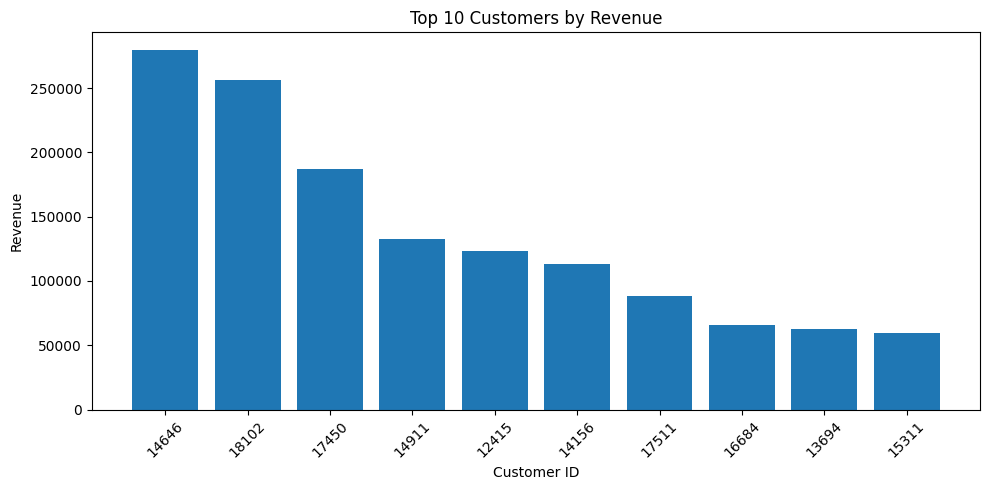

In [21]:
top10 = rfm.sort_values("Monetary", ascending=False).head(10)

plt.figure(figsize=(10, 5))
plt.bar(top10.index.astype(str), top10["Monetary"])

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Revenue")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

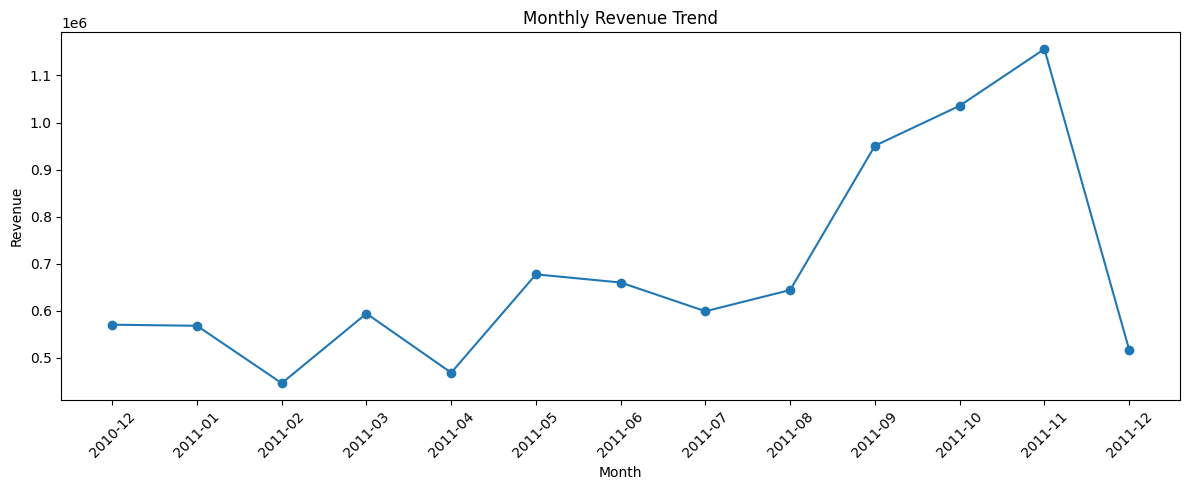

In [22]:
monthly_sales = purchases.groupby(
    purchases["InvoiceDate"].dt.to_period("M")
)["Revenue"].sum()

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales.index.astype(str), monthly_sales.values, marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

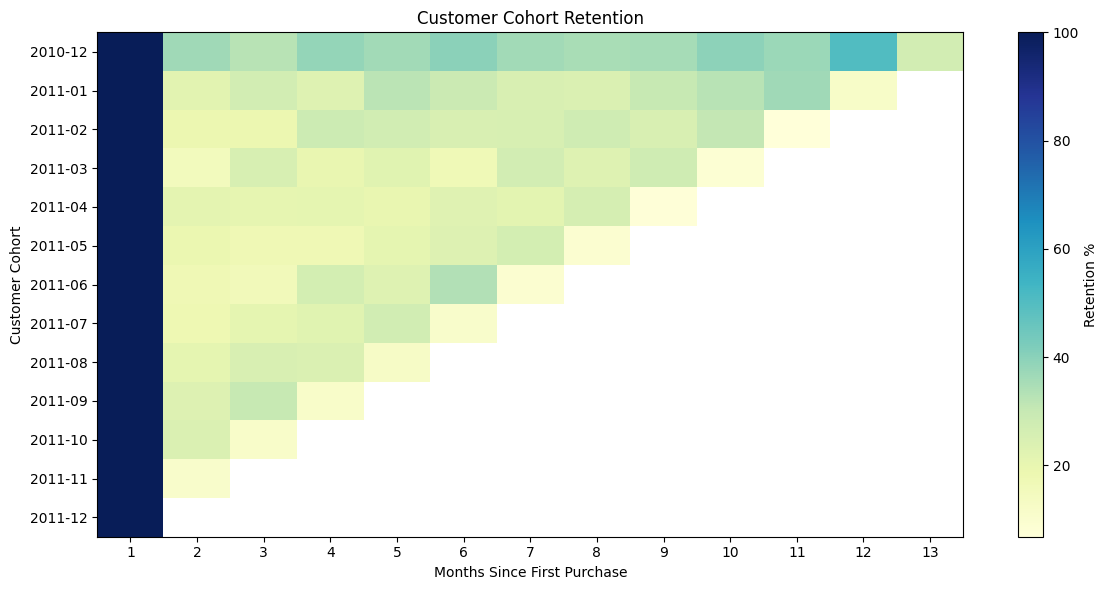

In [23]:
plt.figure(figsize=(12, 6))

plt.imshow(retention, aspect="auto", cmap="YlGnBu")

plt.colorbar(label="Retention %")

plt.title("Customer Cohort Retention")
plt.xlabel("Months Since First Purchase")
plt.ylabel("Customer Cohort")

plt.xticks(
    range(len(retention.columns)),
    retention.columns
)

plt.yticks(
    range(len(retention.index)),
    retention.index.astype(str)
)

plt.tight_layout()
plt.show()

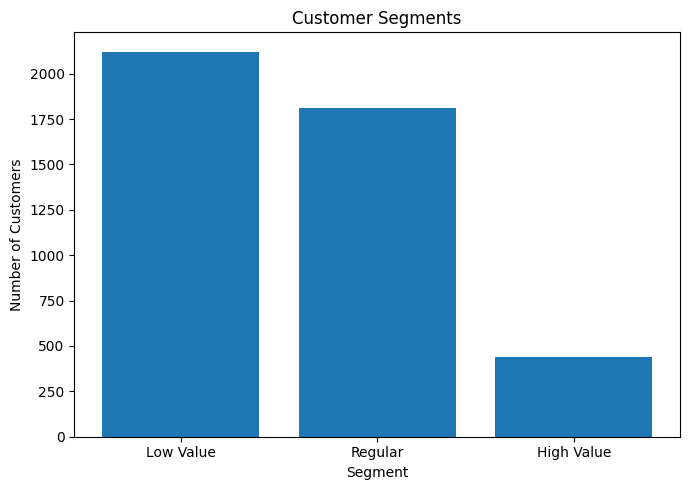

In [24]:
segment_counts = rfm["CustomerSegment"].value_counts()

plt.figure(figsize=(7, 5))
plt.bar(segment_counts.index, segment_counts.values)

plt.title("Customer Segments")
plt.xlabel("Segment")
plt.ylabel("Number of Customers")

plt.tight_layout()
plt.show()

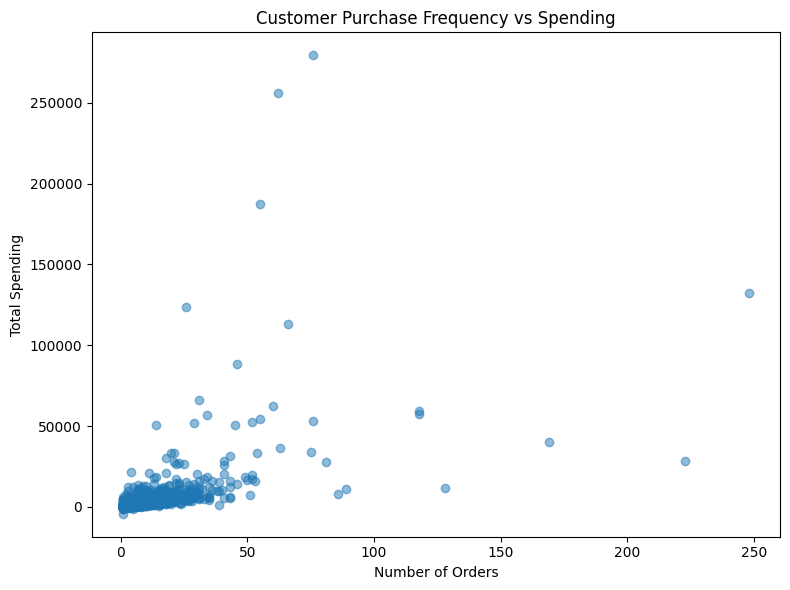

In [25]:
plt.figure(figsize=(8, 6))

plt.scatter(
    rfm["Frequency"],
    rfm["Monetary"],
    alpha=0.5
)

plt.title("Customer Purchase Frequency vs Spending")
plt.xlabel("Number of Orders")
plt.ylabel("Total Spending")

plt.tight_layout()
plt.show()

In [26]:
lifetime_scenarios = [3, 6, 12]

for months in lifetime_scenarios:
    clv = average_monthly_revenue_per_customer * months

    print(
        f"{months} months CLV:",
        round(clv, 2)
    )

3 months CLV: 2037.76
6 months CLV: 4075.51
12 months CLV: 8151.03


In [27]:
# Net revenue includes negative quantity transactions
net_revenue = df["Revenue"].sum()

# Gross revenue from positive purchase transactions
gross_revenue = df.loc[
    df["Quantity"] > 0, "Revenue"
].sum()

print("Gross sales:", round(gross_revenue, 2))
print("Net sales including negative transactions:", round(net_revenue, 2))
print("Difference:", round(gross_revenue - net_revenue, 2))

Gross sales: 8887208.89
Net sales including negative transactions: 8278519.42
Difference: 608689.47


In [28]:
revenue_original = rfm["Monetary"].sum()

revenue_without_outliers = rfm.loc[
    rfm["Monetary"] <= upper_bound, "Monetary"
].sum()

print("Revenue including all customers:", revenue_original)
print("Revenue without high-spending outliers:", revenue_without_outliers)

Revenue including all customers: 8278519.424
Revenue without high-spending outliers: 3363667.354


In [29]:
# Save cleaned transaction data
df.to_csv("cleaned_transactions.csv", index=False)

# Save RFM table
rfm.to_csv("customer_rfm_analysis.csv")

# Save cohort retention table
retention.to_csv("cohort_retention.csv")

# Save segment summary
segment_summary.to_csv("customer_segment_summary.csv")

print("Project files saved successfully!")

Project files saved successfully!


In [30]:
# Save cleaned transaction data
df.to_csv("cleaned_transactions.csv", index=False)

# Save RFM table
rfm.to_csv("customer_rfm_analysis.csv")

# Save cohort retention table
retention.to_csv("cohort_retention.csv")

# Save segment summary
segment_summary.to_csv("customer_segment_summary.csv")

print("Project files saved successfully!")

Project files saved successfully!
